# 7. STEP 6 – 클래스 불균형 처리 및 성능 개선
## 이상치 심화전처리·Baseline 연계 · 실제 실행 결과

**연결 자료:** `STEP4_강판결함_이상치_심화전처리_완성(1).ipynb` 및 STEP 5 이상치 심화전처리 Baseline 결과.  
**질문:** 소수 결함의 누락을 줄이면서 전체 성능을 유지할 수 있는가? 가중치·재표본추출의 변화가 모델 튜닝의 변화와 구별되는가?

원본 **1,941건·27개 입력**과 Train/Valid/Test **1,358/291/292**를 유지합니다. 37개 조건을 사전 기록하고, 원시 Train의 3→5-fold 후보 그룹 CV로 승격한 뒤 Valid에서 비교합니다. 개선 기준이 충족되지 않으면 기존 기준선을 유지합니다.

> **해석 한계:** 동일 Valid와 Test는 이전 작업에서 이미 사용·공개됐습니다. 이번 단계에서 Test를 새로 모델 선택에 사용하지 않았어도, 결과는 새로운 독립 검증이 아닙니다. 성능 개선을 입증하려면 신규 배치 데이터가 필요합니다.

**평가 항목 보완:** 아래 7-1~7-4 절에 동일 RF120·6조건의 실제 Pipeline 비교와 Macro Recall·소수 F1 전후 표를 추가했습니다. 기존 37조건 연구와 추가 36회 적합을 구분합니다.

> **Windows 호환 수정:** 텍스트 파일을 UTF-8로 명시해 읽고, 프로토콜의 상대 경로를 `/`로 통일했습니다. 기존 학습 결과와 캐시를 그대로 사용합니다. 먼저 필요한 패키지를 설치하고, 커널을 다시 시작한 뒤 위에서부터 실행하세요.


## 0. 실행 환경과 파일 구성

전체 ZIP을 해제한 프로젝트 폴더에서 Python 3.12로 `pip install -r requirements.txt` 후 실행합니다. `steel_models.py`는 안정된 모델 클래스를, `step6_experiments.py`는 실험·선정 규칙을, `step6_report.py`는 실측 보고서 생성을 담당합니다.

실제 계산한 CV 결과를 함께 제공합니다. 재실행 시 프로토콜 서명을 검사한 캐시를 불러오며, 캐시가 없으면 아래 코드가 학습을 실행합니다. 출력의 `loaded actual experiment cache`는 실제 결과 재사용을 뜻합니다. 새 학습이 필요하면 프로젝트를 복사한 뒤 `outputs_step6`를 제거하세요. 원본·이전 결과는 `step5_reference`에 보존되어 있습니다.

In [1]:
from pathlib import Path
import sys,json,platform
import numpy as np
import pandas as pd
from IPython.display import display,Image,HTML,Code
candidates=[Path.cwd(),Path.cwd()/'steel_fault_step6',Path.cwd().parent/'steel_fault_step6']
ROOT=next((p.resolve() for p in candidates if (p/'step6_experiments.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('전체 ZIP의 steel_fault_step6 폴더에서 실행하세요.')
sys.path.insert(0,str(ROOT))
import step6_experiments as e
from steel_models import SteelFaultModel,EqualProbabilityEnsemble,sample_weights,LABELS
from step6_report import build_report
pd.set_option('display.max_columns',30)
print('Project:',ROOT)
print('Python:',platform.python_version())

Project: C:\Users\sgr10\Desktop\steel_fault_project\steel_fault_step6
Python: 3.14.4


## 1. STEP 4·5 계보와 입력 검증

원본 NNA·변수명 파일·STEP 4 노트북을 보존하고 기존 분할을 재현합니다. STEP 5에서 검증한 9개 전처리 행렬과 변환 통계도 대조합니다. 이번 단계의 전처리는 **기본 표준화 하나로 고정**하여 불균형 처리 효과를 분리합니다. 정답·행 번호를 모델 입력으로 사용하지 않습니다.

기존 면적 IQR 후보와 밝기 관계 검토 대상 원본 519·592행은 삭제·수정하지 않습니다. RUS로 줄이는 것은 해당 학습용 복사본뿐입니다.

In [2]:
data=e.load_data()
display(data['checks'])
display(data['class_summary'].round(4))
print('Train 최대/최소 클래스 비:',round(data['counts'].train.max()/data['counts'].train.min(),2))
print('기준선: StandardScaler + HistGradientBoosting, 100회·학습률0.1·리프31')

,strategy,split,rows,features,exact_csv_transform_match,binary_preserved,fit_statistics_train_only,deleted_rows,missing
0,standard,train,1358,27,True,True,True,0,0
1,standard,valid,291,27,True,True,True,0,0
2,standard,test,292,27,True,True,True,0,0
3,robust,train,1358,27,True,True,True,0,0
4,robust,valid,291,27,True,True,True,0,0
5,robust,test,292,27,True,True,True,0,0
6,log1p_standard,train,1358,27,True,True,True,0,0
7,log1p_standard,valid,291,27,True,True,True,0,0
8,log1p_standard,test,292,27,True,True,True,0,0


,train,valid,test,train_share,sqrt_weight,balanced_weight,rare_train_lt_5pct
class,,,,,,,
Pastry,110,24,24,0.0810,1.4330,1.7636,False
Z_Scratch,133,28,29,0.0979,1.3032,1.4586,False
K_Scatch,273,59,59,0.2010,0.9096,0.7106,False
Stains,50,11,11,0.0368,2.1255,3.8800,True
Dirtiness,39,8,8,0.0287,2.4067,4.9744,True
Bumps,282,60,60,0.2077,0.8950,0.6879,False
Other_Faults,471,101,101,0.3468,0.6925,0.4119,False


Train 최대/최소 클래스 비: 12.08
기준선: StandardScaler + HistGradientBoosting, 100회·학습률0.1·리프31


## 2. 불균형 평가와 가중치

Train 비중 5% 미만인 **Stains·Dirtiness**를 이번 희소 유형으로 정했습니다. 주 지표는 **Macro F1**, 보조 지표는 Accuracy, Balanced Accuracy, 7개 Recall, 희소 유형 평균 Recall입니다. Macro F1은 클래스별 F1의 같은 비중 평균이며, Balanced Accuracy는 클래스별 Recall의 평균입니다.

클래스 c의 기본 가중치는 $w_c=n/(7n_c)$입니다. 완전 역빈도(`balanced_weight`)와 제곱근 역빈도(`sqrt_weight`)를 비교하며, 가중치는 표본 평균 1로 정규화합니다. 예를 들어 Train Dirtiness는 4.9744, Other_Faults는 0.4119의 완전 역빈도 가중치를 갖습니다. **매 fold의 학습 정답만으로 다시 계산**합니다.

가중치와 재표본추출을 중복 적용하지 않습니다. 가중치가 크다고 예측이 반드시 좋아지는 것은 아니므로 실제 Recall·오분류·전체 성능으로 판단합니다.

In [3]:
train_y=data['parts']['train']['y']
weights=sample_weights(train_y,1.)
assert np.isclose(weights.mean(),1.)
weight_totals=pd.Series(weights,index=train_y.index).groupby(train_y).sum().reindex(LABELS)
display(weight_totals.rename('클래스별 가중 손실 표본 합계').to_frame())
print('모든 클래스의 가중 표본 합계가 같음:',np.allclose(weight_totals,weight_totals.iloc[0]))

,클래스별 가중 손실 표본 합계
Fault,
Pastry,194.0
Z_Scratch,194.0
K_Scatch,194.0
Stains,194.0
Dirtiness,194.0
Bumps,194.0
Other_Faults,194.0


모든 클래스의 가중 표본 합계가 같음: True


## 3. 재표본추출 설계와 합성 표본 정합성

| 방식 | 학습 부분에서만 적용하는 규칙 | 주의할 점 |
|---|---|---|
| ROS | 최대 클래스의 절반보다 적은 유형을 그 수까지 원본 복제 | 정보량 자체가 늘지는 않음 |
| RUS | 클래스 건수 중앙값을 상한으로 큰 유형을 축소 | 다수 유형 정보 손실 |
| SMOTENC | ROS와 같은 목표 수의 합성 표본 생성 | 진단 전용, 최종 선정 제외 |

Train 전체 기준 ROS는 1,358→1,970건, RUS는 1,358→731건입니다. 실제 CV에서는 fold 학습 부분의 빈도로 다시 계산합니다. Valid와 Test는 **재표본추출하지 않고 원래 분포를 유지**합니다.

SMOTENC는 강종 A300과 이산형 Outside_Global_Index를 범주로 보존하고, A400=1−A300으로 복원합니다. 이렇게 해도 면적과 로그면적처럼 함께 제공된 파생 특성의 관계는 자동 보장되지 않으므로, 정합성 감사와 성능 진단에만 사용합니다. 정합성을 맞추기 위한 임의 반올림·값 교정은 하지 않습니다.

모델의 `fit()` 안에서 전처리 적합 → 학습 표본 조정 → 가중치 계산 → 모델 적합을 수행합니다. `predict()`에서는 변환·예측만 수행합니다. 구현은 아래 파일에 있습니다.

In [4]:
display(Code(filename=str(ROOT/'steel_models.py'),language='python'))

"""Portable fold-local preprocessing, balancing, and classifiers for STEP 6."""
from __future__ import annotations
from copy import deepcopy
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import ConvergenceWarning
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from threadpoolctl import threadpool_limits

LABELS=['Pastry','Z_Scratch','K_Scatch','Stains','Dirtiness','Bumps','Other_Faults']
BINARY=['TypeOfSteel_A300','TypeOfSteel_A400']


def make_preprocessor(features):
    continuous=[c for c in features if c not in BINARY]
    return ColumnTransformer([
        ('continuous',Pipeline([('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),
                               ('scaler',StandardScaler())]),continuous),
        ('steel_binary',Pipeline([('imputer',SimpleImputer(strategy='most_frequent',keep_empty_features=True))]),BINARY)
    ],remainder='drop',sparse_threshold=0,verbose_feature_names_out=False)


def sample_weights(y,alpha):
    y=np.asarray(y);labels,counts=np.unique(y,return_counts=True)
    byclass=dict(zip(labels,len(y)/(len(labels)*counts)))
    w=np.array([byclass[v]**alpha for v in y],dtype=float)
    return w/w.mean()


def make_native(family,params,seed):
    if family=='LogisticRegression':
        return LogisticRegression(C=1,solver='lbfgs',max_iter=5000,tol=1e-4,random_state=seed,**params)
    if family=='RandomForest':
        return RandomForestClassifier(n_estimators=300,max_features='sqrt',min_samples_leaf=1,n_jobs=1,random_state=seed,**params)
    if family=='HistGradientBoosting':
        p=dict(max_iter=100,learning_rate=.1,max_leaf_nodes=31,early_stopping=False,random_state=seed)
        p.update(params);return HistGradientBoostingClassifier(**p)
    if family=='ExtraTrees':
        p=dict(n_estimators=400,max_features=1.,min_samples_leaf=1,n_jobs=1,random_state=seed)
        p.update(params);return ExtraTreesClassifier(**p)
    if family=='CatBoost':
        from catboost import CatBoostClassifier
        p=dict(iterations=600,learning_rate=.05,depth=5,l2_leaf_reg=5,loss_function='MultiClass',
               verbose=False,allow_writing_files=False,thread_count=1,random_seed=seed)
        p.update(params);return CatBoostClassifier(**p)
    raise ValueError(family)


class SteelFaultModel(ClassifierMixin,BaseEstimator):
    """All fitting, balancing, and class-weight computation are inside fit().

    fit never receives fold validation rows. predict only transforms: it never
    resamples and never adjusts the evaluation class distribution.
    """
    def __init__(self,family='HistGradientBoosting',params=None,balance='none',seed=42):
        self.family=family;self.params=params;self.balance=balance;self.seed=seed

    def _matrix(self,x):
        return pd.DataFrame(self.preprocessor_.transform(x[self.feature_names_in_]),
            index=x.index,columns=self.preprocessor_.get_feature_names_out())[self.feature_names_in_]

    def fit(self,x,y):
        if not isinstance(x,pd.DataFrame):raise TypeError('A raw-feature DataFrame is required')
        self.feature_names_in_=np.asarray(x.columns,dtype=object);self.n_features_in_=x.shape[1]
        assert self.n_features_in_==27 and set(BINARY).issubset(x.columns)
        assert not set(LABELS+['Fault','original_index','row_1based'])&set(x.columns)
        self.fit_indices_=np.asarray(x.index);self.original_fit_rows_=len(x)
        self.preprocessor_=make_preprocessor(list(x.columns)).fit(x)
        z=

## 4. 37개 후보와 실험·선택 규칙 사전 고정

- **고정 모델의 불균형 조정 15종:** LR 가중치 3종 + RF 6종 + HGB 6종.
- **튜닝·신규 모델 22종:** HGB 8종 + ExtraTrees 6종 + CatBoost 8종.
- 입력 27열과 STEP 4 표준화를 고정합니다. 신규 특성·클리핑·변수 선택은 적용하지 않습니다.
- Train 3-fold 후보 그룹 CV → 계열별·불균형 방식별 최상위 승격 → 동일 Train 5-fold CV.
- 서로 다른 상위 두 모델 계열의 확률을 **1:1로 평균한 앙상블 1종**만 추가합니다. Valid에서 혼합 비중을 탐색하지 않습니다.
- 선택은 Valid Macro F1 → Balanced Accuracy → ID 순서입니다.
- **채택 조건:** Accuracy가 기준선보다 1%p 넘게 낮아지지 않을 것, 희소 유형 평균 Recall·Dirtiness Recall이 기준선 이상일 것, Macro F1이 0.005 이상 증가할 것. 모두 미충족이면 기준선 유지.
- 조건·중단 규칙을 기록한 후 Test 결과에 따른 추가 탐색은 하지 않습니다.

이 수용 기준은 실용적인 실험 기준이며 통계적 유의성 기준은 아닙니다.

In [5]:
specs=e.space()
protocol=e.freeze_protocol(data,specs)
space_table=pd.DataFrame([{**{k:v for k,v in s.items() if k!='params'},'params':json.dumps(s['params'],ensure_ascii=False)} for s in specs])
e.save(space_table,'00_search_space.csv')
display(space_table)
print('사전 고정 시각:',protocol['recorded_at_utc'])
print('조건 수:',len(specs))

,id,phase,family,balance,eligible,params
0,A_LR_none,controlled_ablation,LogisticRegression,none,True,{}
1,A_LR_sqrt_weight,controlled_ablation,LogisticRegression,sqrt_weight,True,{}
2,A_LR_balanced_weight,controlled_ablation,LogisticRegression,balanced_weight,True,{}
3,A_RF_none,controlled_ablation,RandomForest,none,True,{}
4,A_RF_sqrt_weight,controlled_ablation,RandomForest,sqrt_weight,True,{}
5,A_RF_balanced_weight,controlled_ablation,RandomForest,balanced_weight,True,{}
6,A_RF_ros_half,controlled_ablation,RandomForest,ros_half,True,{}
7,A_RF_rus_median,controlled_ablation,RandomForest,rus_median,True,{}
8,A_RF_smotenc_half,controlled_ablation,RandomForest,smotenc_half,False,{}
9,A_HGB_none,controlled_ablation,HistGradientBoosting,none,True,{}


사전 고정 시각: 2026-10-15T03:55:39.544151+00:00
조건 수: 37


## 5. Train 내부 3-fold 후보 그룹 교차검증

STEP 4의 유사 후보 중 **Train–Train** 관계만 연결 성분으로 묶어 fold를 구성합니다. 같은 후보 그룹이 학습과 평가 양쪽에 들어가지 않는지 검사합니다. 이는 실제 코일·배치 ID에 근거한 독립성 검증을 대신하지 못합니다.

모든 조건에 같은 fold를 사용하고 전처리·가중치·재표본추출을 fold 학습 부분에서 다시 적합합니다. 매 적합의 실제 표본 수·클래스 건수·가중치·합성 정합성은 JSON으로, OOF 확률·예측은 NPZ로 저장합니다.

In [6]:
folds3,groups=e.groups_and_folds(data,3)
screen=e.run_cv_stage(specs,data,folds3,'screen3',protocol['signature'],workers=2)
display(screen[['candidate','family','balance','cv_macro_f1_mean','cv_macro_f1_std','cv_accuracy_mean','oof_recall_Stains','oof_recall_Dirtiness']].round(4))

screen3 : loaded actual experiment cache for 37 candidates


,candidate,family,balance,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,oof_recall_Stains,oof_recall_Dirtiness
23,B_ET_01,ExtraTrees,none,0.8147,0.0302,0.7820,0.90,0.8718
11,A_HGB_balanced_weight,HistGradientBoosting,balanced_weight,0.8128,0.0366,0.7806,0.92,0.8462
29,B_CB_01,CatBoost,none,0.8097,0.0305,0.7784,0.90,0.8462
26,B_ET_04,ExtraTrees,balanced_weight,0.8089,0.0301,0.7725,0.92,0.8718
16,B_HGB_02,HistGradientBoosting,sqrt_weight,0.8085,0.0309,0.7725,0.94,0.8205
24,B_ET_02,ExtraTrees,sqrt_weight,0.8080,0.0307,0.7784,0.90,0.8718
34,B_CB_06,CatBoost,none,0.8079,0.0319,0.7739,0.92,0.8205
25,B_ET_03,ExtraTrees,none,0.8078,0.0309,0.7784,0.90,0.8462
27,B_ET_05,ExtraTrees,sqrt_weight,0.8074,0.0283,0.7762,0.92,0.8974
14,A_HGB_smotenc_half,HistGradientBoosting,smotenc_half,0.8060,0.0211,0.7769,0.96,0.8205


### 불균형 처리 자체의 효과

고정 모델 A 조건끼리 비교합니다. 뒤의 신규 모델·튜닝 결과와 섞어 불균형 처리의 효과를 주장하지 않습니다. 평균±SD는 fold 변동이며 신뢰구간이 아닙니다.

In [7]:
ablation=screen.loc[screen.phase.eq('controlled_ablation')].copy()
display(ablation[['candidate','family','balance','cv_macro_f1_mean','cv_macro_f1_std','oof_accuracy','oof_rare_recall_mean','oof_recall_Dirtiness']].round(4))

,candidate,family,balance,cv_macro_f1_mean,cv_macro_f1_std,oof_accuracy,oof_rare_recall_mean,oof_recall_Dirtiness
11,A_HGB_balanced_weight,HistGradientBoosting,balanced_weight,0.8128,0.0366,0.7806,0.8831,0.8462
14,A_HGB_smotenc_half,HistGradientBoosting,smotenc_half,0.8060,0.0211,0.7769,0.8903,0.8205
9,A_HGB_none,HistGradientBoosting,none,0.8049,0.0318,0.7747,0.8674,0.7949
12,A_HGB_ros_half,HistGradientBoosting,ros_half,0.8012,0.0330,0.7695,0.8674,0.7949
10,A_HGB_sqrt_weight,HistGradientBoosting,sqrt_weight,0.7975,0.0319,0.7651,0.8931,0.8462
8,A_RF_smotenc_half,RandomForest,smotenc_half,0.7854,0.0438,0.7563,0.8474,0.7949
6,A_RF_ros_half,RandomForest,ros_half,0.7854,0.0446,0.7526,0.8603,0.8205
4,A_RF_sqrt_weight,RandomForest,sqrt_weight,0.7849,0.0381,0.7541,0.8603,0.8205
3,A_RF_none,RandomForest,none,0.7818,0.0443,0.7526,0.8374,0.7949
5,A_RF_balanced_weight,RandomForest,balanced_weight,0.7803,0.0357,0.7496,0.8603,0.8205


## 6. 승격 조건의 Train 5-fold 검증과 앙상블 고정

승격은 Train CV만으로 수행합니다. 계열별 최상위와 불균형 방식별 최상위에 기준선을 항상 포함하고 SMOTENC 진단 1종을 포함합니다. 3-fold와 5-fold는 분할이 달라 점수 차이를 순수한 개선 효과로 해석하지 않습니다. 앙상블 구성은 Valid를 확인하기 전에 고정합니다.

In [8]:
promoted=e.promoted_specs(screen,specs)
folds5,_=e.groups_and_folds(data,5)
refined=e.run_cv_stage(promoted,data,folds5,'refine5',protocol['signature'],workers=2)
ensemble_spec,ensemble_cv=e.ensemble_plan(refined,promoted,data,folds5)
display(refined[['candidate','family','balance','cv_macro_f1_mean','cv_macro_f1_std','cv_accuracy_mean','oof_rare_recall_mean']].round(4))
print('앙상블 구성:',[s['id'] for s in ensemble_spec['members']],'가중치 1:1')
display(pd.DataFrame([ensemble_cv]).round(4))

refine5 : loaded actual experiment cache for 10 candidates


,candidate,family,balance,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,oof_rare_recall_mean
1,A_HGB_balanced_weight,HistGradientBoosting,balanced_weight,0.8245,0.0183,0.7931,0.8803
0,B_ET_01,ExtraTrees,none,0.8198,0.0186,0.7931,0.8987
5,A_HGB_none,HistGradientBoosting,none,0.8168,0.0201,0.7864,0.8803
7,A_HGB_sqrt_weight,HistGradientBoosting,sqrt_weight,0.8165,0.0155,0.7769,0.8903
6,A_HGB_ros_half,HistGradientBoosting,ros_half,0.8126,0.0257,0.7813,0.8831
9,A_HGB_smotenc_half,HistGradientBoosting,smotenc_half,0.8097,0.0270,0.7754,0.8903
2,B_CB_01,CatBoost,none,0.8058,0.0261,0.7754,0.8803
3,A_RF_ros_half,RandomForest,ros_half,0.8055,0.0331,0.7710,0.8859
8,A_RF_rus_median,RandomForest,rus_median,0.7693,0.0232,0.7283,0.9087
4,A_LR_none,LogisticRegression,none,0.7260,0.0570,0.7128,0.7877


앙상블 구성: ['A_HGB_balanced_weight', 'B_ET_01'] 가중치 1:1


,candidate,phase,family,balance,eligible,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_rare_recall_mean,oof_accuracy,oof_macro_f1,oof_balanced_accuracy,oof_weighted_f1,oof_rare_recall_mean,oof_recall_Pastry,oof_recall_Z_Scratch,oof_recall_K_Scatch,oof_recall_Stains,oof_recall_Dirtiness,oof_recall_Bumps,oof_recall_Other_Faults,fit_seconds
0,E_equal_top2,ensemble,EqualEnsemble,member-specific,True,0.8344,0.0225,0.8005,0.9057,0.8004,0.8353,0.8289,0.8011,0.9059,0.6545,0.9398,0.9707,0.94,0.8718,0.6738,0.7516,0.0


## 7. Validation 비교와 채택 여부 확정

각 후보를 원시 Train 1,358건으로 학습해 원래 Valid 291건에 평가합니다. 기준선의 Valid 예측과 STEP 5 저장 예측의 정확한 일치를 확인합니다. 모델 저장·재로딩의 예측 일치도 확인합니다.

최고 점수뿐 아니라 사전에 정한 Accuracy·희소 유형 Recall·Macro F1 증가 조건을 모두 검사합니다. 이 단계에서 선정 파일을 저장하고 이후 Test 결과에 따라 바꾸지 않습니다.

In [9]:
comparison=e.fit_validation(data,promoted,ensemble_spec,refined,ensemble_cv)
selection=e.select_winner(comparison)
display(pd.read_csv(e.OUT/'09_selection_gates.csv')[['candidate','balance','valid_accuracy','valid_macro_f1','valid_rare_recall_mean','valid_recall_Dirtiness','accepted_improvement']].round(4))
print('선정:',selection['candidate'])
print('개선 수용 기준 통과:',selection['meaningful_valid_gain'])
print('Test 전 고정 시각:',selection['frozen_at_utc'])

Loading fixed Validation comparison (no refit).


,candidate,balance,valid_accuracy,valid_macro_f1,valid_rare_recall_mean,valid_recall_Dirtiness,accepted_improvement
0,A_HGB_none,none,0.7869,0.7651,0.5966,0.375,False
1,A_HGB_balanced_weight,balanced_weight,0.7904,0.7645,0.5966,0.375,False
2,A_HGB_sqrt_weight,sqrt_weight,0.7835,0.7584,0.5966,0.375,False
3,E_equal_top2,member-specific,0.7869,0.7577,0.5966,0.375,False
4,A_HGB_smotenc_half,smotenc_half,0.7663,0.7471,0.5966,0.375,False
5,A_RF_ros_half,ros_half,0.7491,0.7470,0.6591,0.500,False
6,A_HGB_ros_half,ros_half,0.7595,0.7389,0.5966,0.375,False
7,B_ET_01,none,0.7698,0.7385,0.5966,0.375,False
8,B_CB_01,none,0.7698,0.7366,0.5966,0.375,False
9,A_RF_rus_median,rus_median,0.7113,0.7226,0.6591,0.500,False


선정: A_HGB_none
개선 수용 기준 통과: False
Test 전 고정 시각: 2026-10-15T04:00:15.023788+00:00


## 8. paired 차이 분석과 유사 후보 민감도

개선 후보가 채택되면 그 모델과 기준선을 비교합니다. **기준선 유지로 결론이 나면 최고 비기준선 대안을 진단용으로 비교**합니다. 이 진단은 채택 규칙이나 선정 결과를 바꾸지 않습니다.

클래스별 Valid 건수를 고정한 paired bootstrap 2,000회의 구간을 제공합니다. 두 고정 모델의 관측 표본 변동만 반영하며, 후보 탐색·Valid 반복 사용·실제 배치 의존성은 반영하지 않습니다. McNemar p값도 탐색적 참고치로만 사용합니다. Train 유사 후보와 연결된 Valid 행을 제외한 평가는 선택 후 민감도 분석입니다.

In [10]:
paired=e.paired_validation_analysis(data,selection)
display(paired.round(4))
changes=json.loads((e.OUT/'11_valid_prediction_changes.json').read_text(encoding="utf-8-sig"))
display(pd.Series(changes,name='Valid 진단 변화').to_frame())
display(pd.read_csv(e.OUT/'12_valid_near_candidate_sensitivity.csv')[['model','rows','accuracy','macro_f1','rare_recall_mean']].round(4))

,comparison_candidate,selected_candidate,metric,paired_delta,bootstrap95_low,bootstrap95_high,n_boot,conditional_on_fixed_models
0,A_HGB_balanced_weight,A_HGB_none,accuracy,0.0034,-0.0241,0.0309,2000,True
1,A_HGB_balanced_weight,A_HGB_none,macro_f1,-0.0006,-0.0209,0.0195,2000,True


,Valid 진단 변화
comparison_candidate,A_HGB_balanced_weight
selected_candidate,A_HGB_none
diagnostic_only,True
new_correct,9
new_wrong,8
both_correct,221
both_wrong,53
prediction_disagreements,19
mcnemar_exact_p,1.0
note,Exploratory conditional summary; repeated Vali...


,model,rows,accuracy,macro_f1,rare_recall_mean
0,STEP5 baseline,286,0.7832,0.7641,0.5966
1,STEP6 diagnostic challenger,286,0.7867,0.7635,0.5966


## 9. 합성 정합성과 실제 학습 표본 수 감사

강종 값 보존만으로 파생변수 관계가 보장되지 않는다는 점을 직접 검사합니다. 아래는 실제 전체 Train 적합의 기록입니다. ROS 복제본의 원본 출처는 해당 Train에만 속하고, RUS는 학습 복사본만 축소하며, 원본 데이터·Valid·Test는 유지됩니다.

In [11]:
audits=json.loads((e.OUT/'08_training_balance_audits.json').read_text(encoding="utf-8-sig"))
audit_view=pd.DataFrame([{k:a.get(k) for k in ['candidate','balance','original_rows','fitted_rows_after_balance','synthetic_rows','source_rows_removed','synthetic_log_area_relation_mismatch','synthetic_noninteger_area','binary_complement_preserved']} for a in audits if 'member' not in a])
display(audit_view)

,candidate,balance,original_rows,fitted_rows_after_balance,synthetic_rows,source_rows_removed,synthetic_log_area_relation_mismatch,synthetic_noninteger_area,binary_complement_preserved
0,B_ET_01,none,1358,1358,0,0,NaN,NaN,True
1,A_HGB_balanced_weight,balanced_weight,1358,1358,0,0,NaN,NaN,True
2,B_CB_01,none,1358,1358,0,0,NaN,NaN,True
3,A_RF_ros_half,ros_half,1358,1970,0,0,NaN,NaN,True
4,A_LR_none,none,1358,1358,0,0,NaN,NaN,True
5,A_HGB_none,none,1358,1358,0,0,NaN,NaN,True
6,A_HGB_ros_half,ros_half,1358,1970,0,0,NaN,NaN,True
7,A_HGB_sqrt_weight,sqrt_weight,1358,1358,0,0,NaN,NaN,True
8,A_RF_rus_median,rus_median,1358,731,0,627,NaN,NaN,True
9,A_HGB_smotenc_half,smotenc_half,1358,1970,612,0,507.0,588.0,True


## 평가 항목 점검 및 보완: 7-1~7-4

기존 파일에는 여러 기법의 CV 결과가 있었지만, **동일 RF의 모든 방법을 같은 Valid에서 비교하는 표**, 직접 `class_weight="balanced"` 실행, 명시적 `imblearn.Pipeline`, 일반 SMOTE 정합성 검사, **Macro Recall·소수 클래스 F1 통합 비교표**가 부족했습니다. 아래에 모두 보완합니다.

이번 추가 비교는 **RF120 고정 6조건**입니다. 기존 37조건 탐색(RF300 포함)과 구분하며 기존 선정 모델을 바꾸지 않습니다. 기존 Valid·Test를 이미 확인한 이후 요청된 설명적 확장 실험이므로 새 독립 검증으로 해석하지 않습니다. 추가 Test 예측은 하지 않습니다.

### 7-1. 실험할 불균형 처리 방법

| 방법 | 원리 | 장점 | 한계 |
|---|---|---|---|
| Class Weight | 소수 유형 오분류에 큰 손실 가중치 | 원본 표본 유지 | 일부 유형 성능 감소 가능 |
| Random Over-sampling | 소수 유형 표본 복제 | 표본 건수 균형·범주 값 보존 | 과적합·중복 증가, 새 정보는 없음 |
| Random Under-sampling | 다수 유형 학습 복사본 축소 | 표본 건수 균형·학습량 감소 | 다수 유형 정보 손실 |
| SMOTE | 같은 유형 이웃 사이 보간 | 복제 외 방식으로 표본 확장 | 강종 중간값·파생 관계 위반 가능 |
| SMOTENC (추가 진단) | 연속형·범주형 생성 분리 | 강종·이산값 보존 | 연속형 파생 관계까지 보장하지 않음 |

공통 조건: 원시 27열, STEP 4 표준화, Train 1,358건·원래 Valid 291건, seed=42, RF 120개 트리. 전처리는 각 학습 fold에서 새로 적합합니다. 이번에는 `sampling_strategy="auto"`로 ROS/SMOTE/SMOTENC를 각 적합 부분의 최다 유형까지, RUS를 최소 유형까지 맞춥니다. 기존 부분 ROS·중앙값 RUS 결과는 별도로 유지합니다.

In [12]:
import step6_rubric as rubric
import inspect, joblib
# 실제 실험에 사용한 imblearn.Pipeline 생성 코드입니다.
display(Code(inspect.getsource(rubric.build_pipeline), language='python'))
# run() 내부에서 매 fold clone(template).fit(...)으로 새로 학습합니다.
# 캐시가 있으면 입력·코드·기존 선정 파일·결과 해시를 검증한 후 읽습니다.
rubric_results = rubric.run(data)
rubric_cv = pd.read_csv(rubric.OUT/'02_train5fold_summary.csv')
rubric_audits = json.loads((rubric.OUT/'08_pipeline_fit_audits.json').read_text(encoding='utf-8-sig'))
print('추가 적합: Train CV 30회 + 전체 Train 6회, Test 추가 예측 0회')

def build_pipeline(features, method):
    # This is the user's RF120 example, controlled identically in all six arms.
    return Pipeline([
        ('preprocess', make_preprocessor(features).set_output(transform='pandas')),
        ('sampler', AuditedSampler(method=method, random_state=42)),
        ('model', RandomForestClassifier(n_estimators=120,
            class_weight='balanced' if method == 'class_weight' else None,
            max_features='sqrt', min_samples_leaf=1, n_jobs=1, random_state=42))])

추가 적합: Train CV 30회 + 전체 Train 6회, Test 추가 예측 0회


### 7-2. Class Weight 적용

예시와 동일하게 `RandomForestClassifier(n_estimators=120, class_weight="balanced", random_state=42)`를 사용했습니다. 실제 학습은 위 `rubric.run(data)`의 `Pipeline.fit()`에서 실행됩니다. 처리 없음과 전처리·RF 설정·fold·Validation을 동일하게 유지하고, **별도의 sample_weight를 중복 적용하지 않습니다**.

가중치는 각 학습 부분의 정답에서 $w_c=n/(7n_c)$로 계산합니다. 전체 Train의 Dirtiness는 약 4.9744, Stains는 3.8800입니다. Validation 비율로 가중치를 계산하지 않습니다.

In [13]:
from sklearn.ensemble import RandomForestClassifier
# 요청하신 직접 class_weight 설정과 실제 Pipeline의 모델 설정을 대조합니다.
model = RandomForestClassifier(n_estimators=120, class_weight="balanced", random_state=42, n_jobs=1)
weight_pipeline = rubric.build_pipeline(list(data['parts']['train']['raw'].columns), 'class_weight')
assert model.get_params() == weight_pipeline.named_steps['model'].get_params()
class_weight_rows = pd.read_csv(rubric.OUT/'05_train_class_counts_and_weights.csv')
display(class_weight_rows.loc[class_weight_rows.method.eq('class_weight')].round(4))
display(rubric.compact_table(rubric_results.loc[rubric_results.method.isin(['none','class_weight'])]).round(4))

,method,class,train_before,train_after,class_weight
7,class_weight,Pastry,110,110,1.7636
8,class_weight,Z_Scratch,133,133,1.4586
9,class_weight,K_Scatch,273,273,0.7106
10,class_weight,Stains,50,50,3.8800
11,class_weight,Dirtiness,39,39,4.9744
12,class_weight,Bumps,282,282,0.6879
13,class_weight,Other_Faults,471,471,0.4119


,불균형 처리,Accuracy,Macro F1,Macro Recall,소수 클래스 F1 평균,소수 클래스 Recall 평균,Dirtiness F1,Dirtiness Recall
0,처리 없음,0.7491,0.7144,0.6796,0.6808,0.5966,0.4615,0.375
1,Class Weight,0.7354,0.7107,0.6691,0.7000,0.5966,0.5000,0.375


### 7-3. SMOTE 적용: Pipeline·fold 내부 처리·강종 검사

실제 구성은 **imblearn.Pipeline(전처리 → AuditedSampler → RF)**입니다. `AuditedSampler` 안에서 공식 SMOTE/SMOTENC/ROS/RUS의 `fit_resample`을 호출하며, 표본 출처와 처리 전후 행렬을 기록합니다. 전체 Train에 SMOTE를 먼저 적용하고 CV로 나누는 방식은 사용하지 않습니다. 평가 시에는 `predict`만 호출하고 sampler는 건너뜁니다.

일반 SMOTE와 SMOTENC를 구분합니다. 샘플러 입력을 float로 통일해 pandas 정수 열 복원 때문에 중간값이 잘리는 문제를 예방하고, **일반 SMOTE의 강종 중간값을 실제 측정**합니다. SMOTENC는 A300·Outside_Global_Index를 범주로 지정하고 A400=1−A300으로 복원합니다. 두 합성 방법 모두 면적–로그면적·픽셀 정수성까지 보장하지 않으므로 진단용으로 한정합니다.

In [14]:
# fit_resample이 실제로 어떻게 수행됐는지 구현과 저장된 행렬을 확인합니다.
display(Code(inspect.getsource(rubric.AuditedSampler), language='python'))
smote_fitted = joblib.load(rubric.OUT/'rf120_smote_pipeline.joblib')
smote_step = smote_fitted.named_steps['sampler']
y_train_before = pd.Series(smote_step.y_before_).value_counts().reindex(LABELS)
y_train_smote = pd.Series(smote_step.y_after_).value_counts().reindex(LABELS)
display(pd.DataFrame({'SMOTE 전':y_train_before, 'SMOTE 후':y_train_smote}))
audit_table = pd.read_csv(rubric.OUT/'09_synthetic_and_pipeline_audit.csv')
display(audit_table[['method','original_fit_rows','fitted_rows','synthetic_rows',
    'removed_training_copies','steel_nonbinary_rows','steel_complement_violation_rows',
    'outside_global_unseen_values_rows','synthetic_log_area_mismatch','synthetic_noninteger_area']])
assert len(rubric_audits)==36
assert all(a['fit_eval_index_overlap']==0 for a in rubric_audits)
assert all(a['fit_eval_candidate_group_overlap']==0 for a in rubric_audits if a['stage']=='Train5fold')
assert all(a['preprocessor_fit_rows']==a['original_fit_rows'] for a in rubric_audits)
assert all(a['sampler_fit_calls_after_prediction']==1 and not a['evaluation_resampled'] for a in rubric_audits)
print('36회 적합: 학습/평가 행 분리·전처리 학습 행 수·평가 행 불변·예측 시 재표본추출 없음 통과')
print('후보 그룹 분리는 Train CV에서 확인했습니다. 기존 Train–Valid 유사 후보 연결 6개는 유지되므로 독립 그룹 평가로 주장하지 않습니다.')
del smote_fitted

class AuditedSampler(BaseEstimator):
    """An imblearn-compatible sampler; records the actual single fit_resample.

    Records are training-only. transform/predict are intentionally absent so the
    imblearn pipeline skips this step at inference, as required by its contract.
    """
    def __init__(self, method='none', random_state=42):
        self.method = method
        self.random_state = random_state

    def fit_resample(self, X, y):
        # Preserve interpolation: imblearn restores DataFrame dtypes. Leaving
        # binary columns as int can silently truncate ordinary SMOTE midpoints.
        # Float input exposes the actual fractional values for an honest audit.
        X = X.astype(float)
        self.fit_calls_ = getattr(self, 'fit_calls_', 0) + 1
        self.fit_indices_ = np.asarray(X.index).copy()
        self.before_ = X.copy()
        self.y_before_ = np.asarray(y).copy()
        self.sampler_ = None
        minimum = int(pd.Series(y).value_counts().min())
        if self.method == 'ros':
            self.sampler_ = RandomOverSampler(random_state=self.random_state)
        elif self.method == 'rus':
            self.sampler_ = RandomUnderSampler(random_state=self.random_state)
        elif self.method == 'smote':
            self.sampler_ = SMOTE(random_state=self.random_state,
                                  k_neighbors=min(5, minimum - 1))
        elif self.method == 'smotenc':
            self.sampler_ = SMOTENC(
                categorical_features=['TypeOfSteel_A300', 'Outside_Global_Index'],
                random_state=self.random_state, k_neighbors=min(5, minimum - 1))
        elif self.method not in ['none', 'class_weight']:
            raise ValueError(self.method)
        if self.sampler_ is None:
            z, yy = X.copy(), np.asarray(y).copy()
        elif self.method == 'smotenc':
            # A400 is the complement of A300, not a second independent category.
            z, yy = self.sampler_.fit_resample(X.drop(columns='TypeOfSteel_A400'), y)
            z['TypeOfSteel_A400'] = 1 - z.TypeOfSteel_A300
            z = z[list(X.columns)]
        else:
            z, yy = self.sampler_.fit_resample(X, y)
        self.after_ = z.copy()
        self.y_after_ = np.asarray(yy).copy()
        if self.method in ['ros', 'smote', 'smotenc']:
            np.testing.assert_array_equal(z.iloc[:len(X)].to_numpy(), X.to_numpy())
        return z, yy

,SMOTE 전,SMOTE 후
Pastry,110,471
Z_Scratch,133,471
K_Scatch,273,471
Stains,50,471
Dirtiness,39,471
Bumps,282,471
Other_Faults,471,471


,method,original_fit_rows,fitted_rows,synthetic_rows,removed_training_copies,steel_nonbinary_rows,steel_complement_violation_rows,outside_global_unseen_values_rows,synthetic_log_area_mismatch,synthetic_noninteger_area
0,none,1358,1358,0,0,0,0,0,0,0
1,class_weight,1358,1358,0,0,0,0,0,0,0
2,ros,1358,3297,0,0,0,0,0,0,0
3,rus,1358,273,0,1085,0,0,0,0,0
4,smote,1358,3297,1939,0,145,0,127,1594,1880
5,smotenc,1358,3297,1939,0,0,0,0,1599,1885


36회 적합: 학습/평가 행 분리·전처리 학습 행 수·평가 행 불변·예측 시 재표본추출 없음 통과
후보 그룹 분리는 Train CV에서 확인했습니다. 기존 Train–Valid 유사 후보 연결 6개는 유지되므로 독립 그룹 평가로 주장하지 않습니다.


### 7-4. 불균형 처리 전후 결과 비교

아래는 모두 **같은 원래 Validation 291건**의 실측입니다.

- **Macro F1**: 7개 클래스 F1의 산술평균.
- **Macro Recall**: 7개 Recall의 산술평균. 이번 모든 평가 분할에서 Balanced Accuracy와 일치를 검사했습니다.
- **소수 클래스 F1**: 원본 Train 비중 5% 미만인 **Stains·Dirtiness F1의 산술평균**. support 가중 평균과 다릅니다.
- 비교 변화량은 **같은 RF120 처리 없음**을 기준으로 계산합니다. 기존 HGB와의 차이를 불균형 처리 효과로 해석하지 않습니다.

CV 평균±표준편차는 fold 간 변동이며 신뢰구간이 아닙니다. CV와 Valid를 섞어 비교하지 않습니다.

후보 그룹 분리는 Train 내부 CV에서 확인했습니다. 기존 Train–Valid 사이에는 유사 후보 연결 6개가 있어, 같은 Valid의 비교를 후보 그룹이 완전히 분리된 독립 평가로 해석하지 않습니다.

In [15]:
display(rubric.compact_table(rubric_results).round(4))
display(rubric_results[['불균형 처리','delta_accuracy','delta_macro_f1','delta_macro_recall',
    'delta_minority_f1_mean','delta_minority_recall_mean','new_correct','new_wrong']].round(4))
print('동일 Train 5-fold 보조 검증 (평균·표준편차 / OOF 별도)')
display(rubric_cv[['method','macro_f1_mean','macro_f1_std','macro_recall_mean',
    'minority_f1_mean_mean','minority_f1_mean_std','oof_macro_f1']].round(4))
class_effects = pd.read_csv(rubric.OUT/'04_valid_class_metrics_and_deltas.csv')
display(class_effects.loc[class_effects['minority'],['method','class','support','precision','recall','f1-score',
    'delta_recall','delta_f1-score']].round(4))
for line in rubric.interpretation(rubric_results):print(line)
print('Dirtiness Valid 8건, Stains 11건: Recall 1건 변화는 각각 12.5%p, 9.09%p입니다.')
print('추가 비교는 기존 HGB 선정·Test 결과를 변경하지 않습니다. 82% 초과 주장은 하지 않습니다.')

,불균형 처리,Accuracy,Macro F1,Macro Recall,소수 클래스 F1 평균,소수 클래스 Recall 평균,Dirtiness F1,Dirtiness Recall
0,처리 없음,0.7491,0.7144,0.6796,0.6808,0.5966,0.4615,0.375
1,Class Weight,0.7354,0.7107,0.6691,0.7000,0.5966,0.5000,0.375
2,Over-sampling,0.7423,0.7260,0.6858,0.7227,0.5966,0.5455,0.375
3,Under-sampling,0.6632,0.6675,0.6938,0.6643,0.5966,0.4286,0.375
4,SMOTE (정합성 진단),0.7560,0.7337,0.7144,0.6808,0.5966,0.4615,0.375
5,SMOTENC (범주형 보강 진단),0.7526,0.7254,0.7029,0.6808,0.5966,0.4615,0.375


,불균형 처리,delta_accuracy,delta_macro_f1,delta_macro_recall,delta_minority_f1_mean,delta_minority_recall_mean,new_correct,new_wrong
0,처리 없음,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0
1,Class Weight,-0.0137,-0.0038,-0.0105,0.0192,0.0,7.0,11.0
2,Over-sampling,-0.0069,0.0115,0.0062,0.0420,0.0,8.0,10.0
3,Under-sampling,-0.0859,-0.0469,0.0142,-0.0165,0.0,23.0,48.0
4,SMOTE (정합성 진단),0.0069,0.0193,0.0348,0.0000,0.0,12.0,10.0
5,SMOTENC (범주형 보강 진단),0.0034,0.0110,0.0233,0.0000,0.0,12.0,11.0


동일 Train 5-fold 보조 검증 (평균·표준편차 / OOF 별도)


,method,macro_f1_mean,macro_f1_std,macro_recall_mean,minority_f1_mean_mean,minority_f1_mean_std,oof_macro_f1
0,none,0.7795,0.0178,0.7641,0.8820,0.0147,0.7805
1,class_weight,0.7928,0.0347,0.7709,0.9003,0.0183,0.7938
2,ros,0.8159,0.0261,0.8108,0.9064,0.0332,0.8166
3,rus,0.6744,0.0248,0.7663,0.7122,0.0536,0.6732
4,smote,0.8072,0.0207,0.8202,0.8851,0.0583,0.8074
5,smotenc,0.8034,0.0157,0.8160,0.8951,0.0483,0.8032


,method,class,support,precision,recall,f1-score,delta_recall,delta_f1-score
3,none,Stains,11.0,1.00,0.8182,0.9000,0.0,0.0000
4,none,Dirtiness,8.0,0.60,0.3750,0.4615,0.0,0.0000
10,class_weight,Stains,11.0,1.00,0.8182,0.9000,0.0,0.0000
11,class_weight,Dirtiness,8.0,0.75,0.3750,0.5000,0.0,0.0385
17,ros,Stains,11.0,1.00,0.8182,0.9000,0.0,0.0000
18,ros,Dirtiness,8.0,1.00,0.3750,0.5455,0.0,0.0839
24,rus,Stains,11.0,1.00,0.8182,0.9000,0.0,0.0000
25,rus,Dirtiness,8.0,0.50,0.3750,0.4286,0.0,-0.0330
31,smote,Stains,11.0,1.00,0.8182,0.9000,0.0,0.0000
32,smote,Dirtiness,8.0,0.60,0.3750,0.4615,0.0,0.0000


Class Weight: 처리 없음 대비 Macro F1 -0.0038, Macro Recall -0.0105, 소수 클래스 F1 평균 +0.0192, Accuracy -1.37%p. 새 정분류 7건·새 오분류 11건.
Over-sampling: 처리 없음 대비 Macro F1 +0.0115, Macro Recall +0.0062, 소수 클래스 F1 평균 +0.0420, Accuracy -0.69%p. 새 정분류 8건·새 오분류 10건.
Under-sampling: 처리 없음 대비 Macro F1 -0.0469, Macro Recall +0.0142, 소수 클래스 F1 평균 -0.0165, Accuracy -8.59%p. 새 정분류 23건·새 오분류 48건.
SMOTE (정합성 진단): 처리 없음 대비 Macro F1 +0.0193, Macro Recall +0.0348, 소수 클래스 F1 평균 +0.0000, Accuracy +0.69%p. 새 정분류 12건·새 오분류 10건.
SMOTENC (범주형 보강 진단): 처리 없음 대비 Macro F1 +0.0110, Macro Recall +0.0233, 소수 클래스 F1 평균 +0.0000, Accuracy +0.34%p. 새 정분류 12건·새 오분류 11건.
기준 RF120의 Valid Accuracy는 74.91%, Macro F1은 0.7144이다. 이 변화량의 기준은 동일 RF120이며, 기존 선정 HGB와의 차이를 불균형 처리 효과로 해석하지 않는다.
Dirtiness Valid 8건, Stains 11건: Recall 1건 변화는 각각 12.5%p, 9.09%p입니다.
추가 비교는 기존 HGB 선정·Test 결과를 변경하지 않습니다. 82% 초과 주장은 하지 않습니다.


## 10. 선정 모델의 기존 Test 참고 평가

선정 모델은 Train 1,358건으로 학습된 상태를 유지합니다. Train+Valid 재학습을 하지 않아 STEP 5와 같은 학습 자료 기준으로 비교합니다. 저장된 기준선 Test 예측을 비교에 재사용하고 선정 모델만 한 번 평가합니다. 재실행은 저장된 Test 결과를 불러옵니다.

동일 Test가 이미 공개되었으므로 새 독립 최종 검증이 아닙니다. 결과가 낮거나 높아도 이 이후 가중치·모델·임계값을 바꾸지 않습니다.

In [16]:
test_result=e.historical_test_reference(data,selection)
display(pd.Series(test_result,name='기존 Test 참고 결과').to_frame())
display(pd.read_csv(e.OUT/'16_test_class_comparison.csv').round(4))

Loading already evaluated historical Test; no repeat prediction.


,기존 Test 참고 결과
candidate,A_HGB_none
accuracy,0.804795
macro_f1,0.819826
balanced_accuracy,0.803044
weighted_f1,0.809388
rare_recall_mean,0.829545
recall_Pastry,0.625
recall_Z_Scratch,0.896552
recall_K_Scatch,0.915254
recall_Stains,0.909091


,model,class,precision,recall,f1-score,support
0,STEP5 baseline,Pastry,0.5000,0.6250,0.5556,24.0
1,STEP5 baseline,Z_Scratch,1.0000,0.8966,0.9455,29.0
2,STEP5 baseline,K_Scatch,0.9818,0.9153,0.9474,59.0
3,STEP5 baseline,Stains,0.9091,0.9091,0.9091,11.0
4,STEP5 baseline,Dirtiness,1.0000,0.7500,0.8571,8.0
5,STEP5 baseline,Bumps,0.7857,0.7333,0.7586,60.0
6,STEP5 baseline,Other_Faults,0.7407,0.7921,0.7656,101.0
7,STEP6 selected,Pastry,0.5000,0.6250,0.5556,24.0
8,STEP6 selected,Z_Scratch,1.0000,0.8966,0.9455,29.0
9,STEP6 selected,K_Scatch,0.9818,0.9153,0.9474,59.0


## 11. 전후 비교 시각화와 실측 보고서

불균형 처리의 단독 효과는 고정 모델 CV로, 최종 채택 여부는 Valid 기준으로 읽습니다. 기준선이 유지된 경우 그래프는 미채택 참고 대안의 변화도 보여줍니다. 소수 유형의 1건 변화가 크므로 표본 수를 함께 확인합니다.

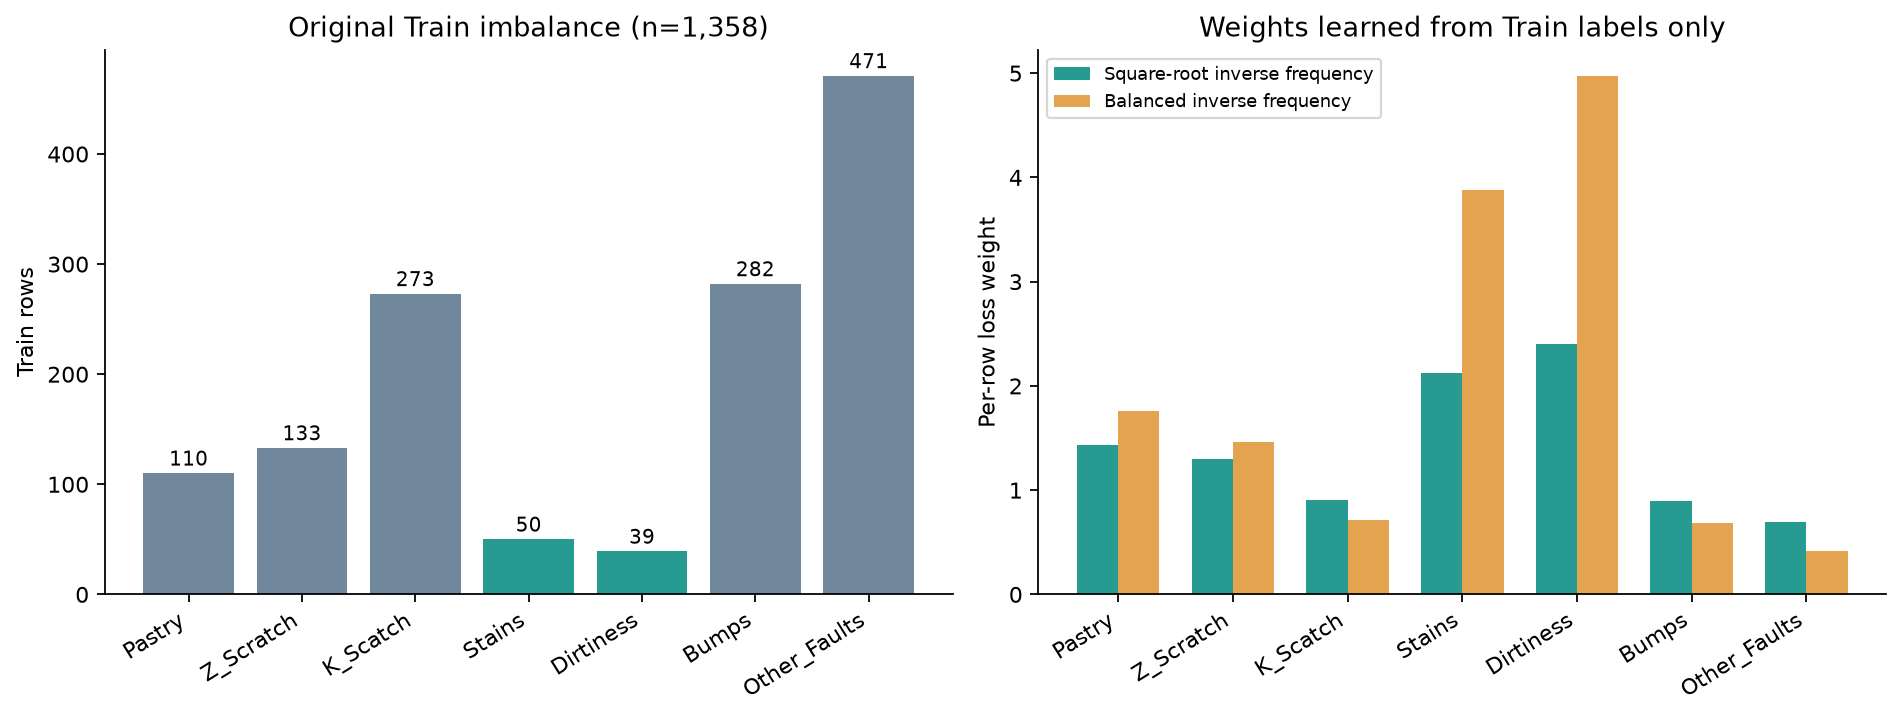

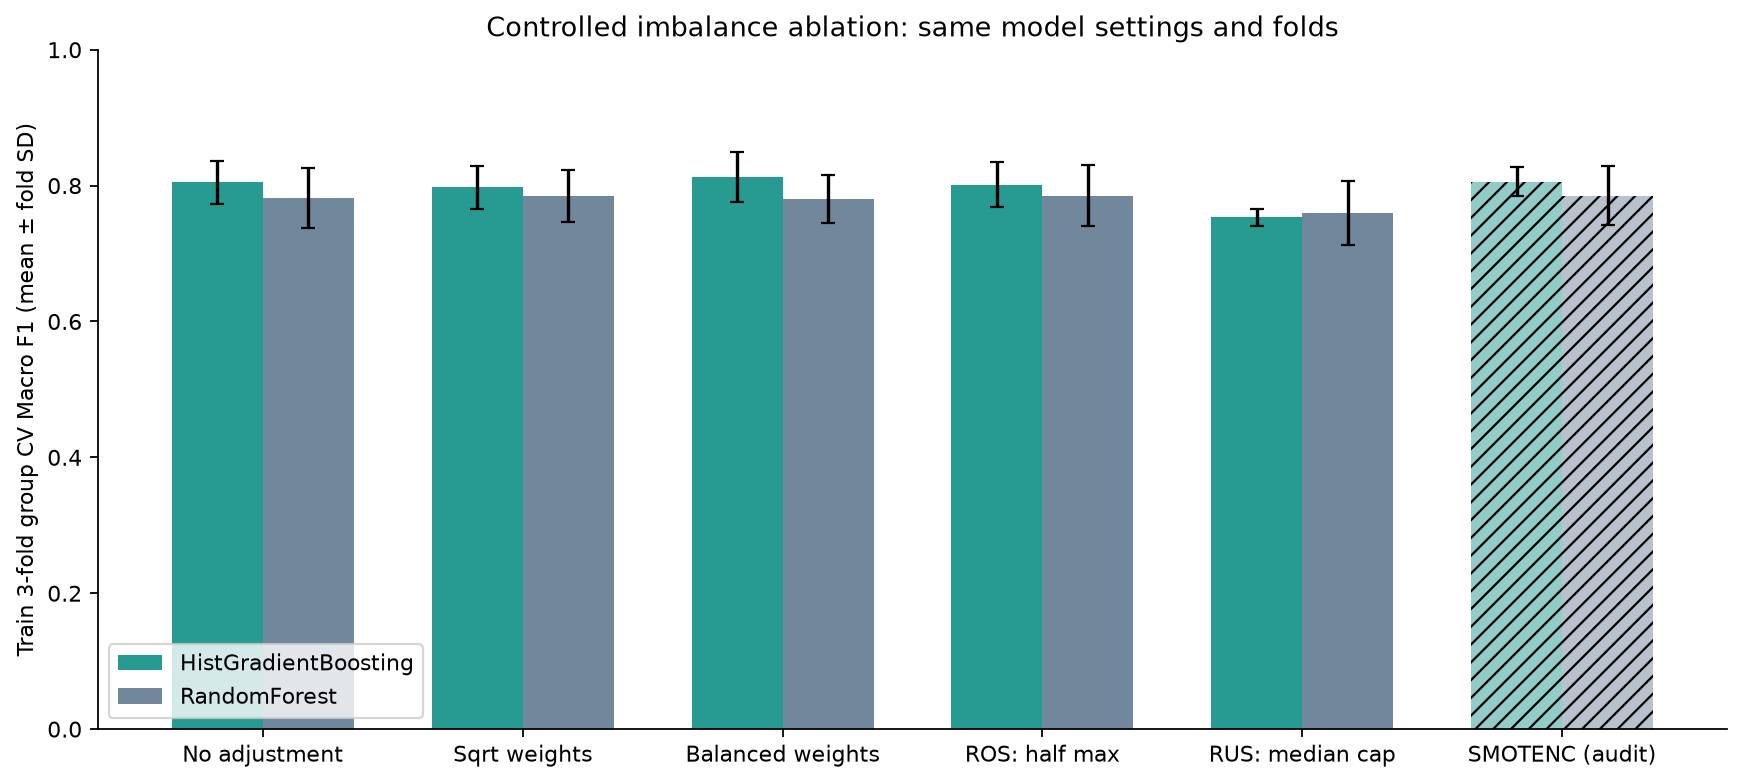

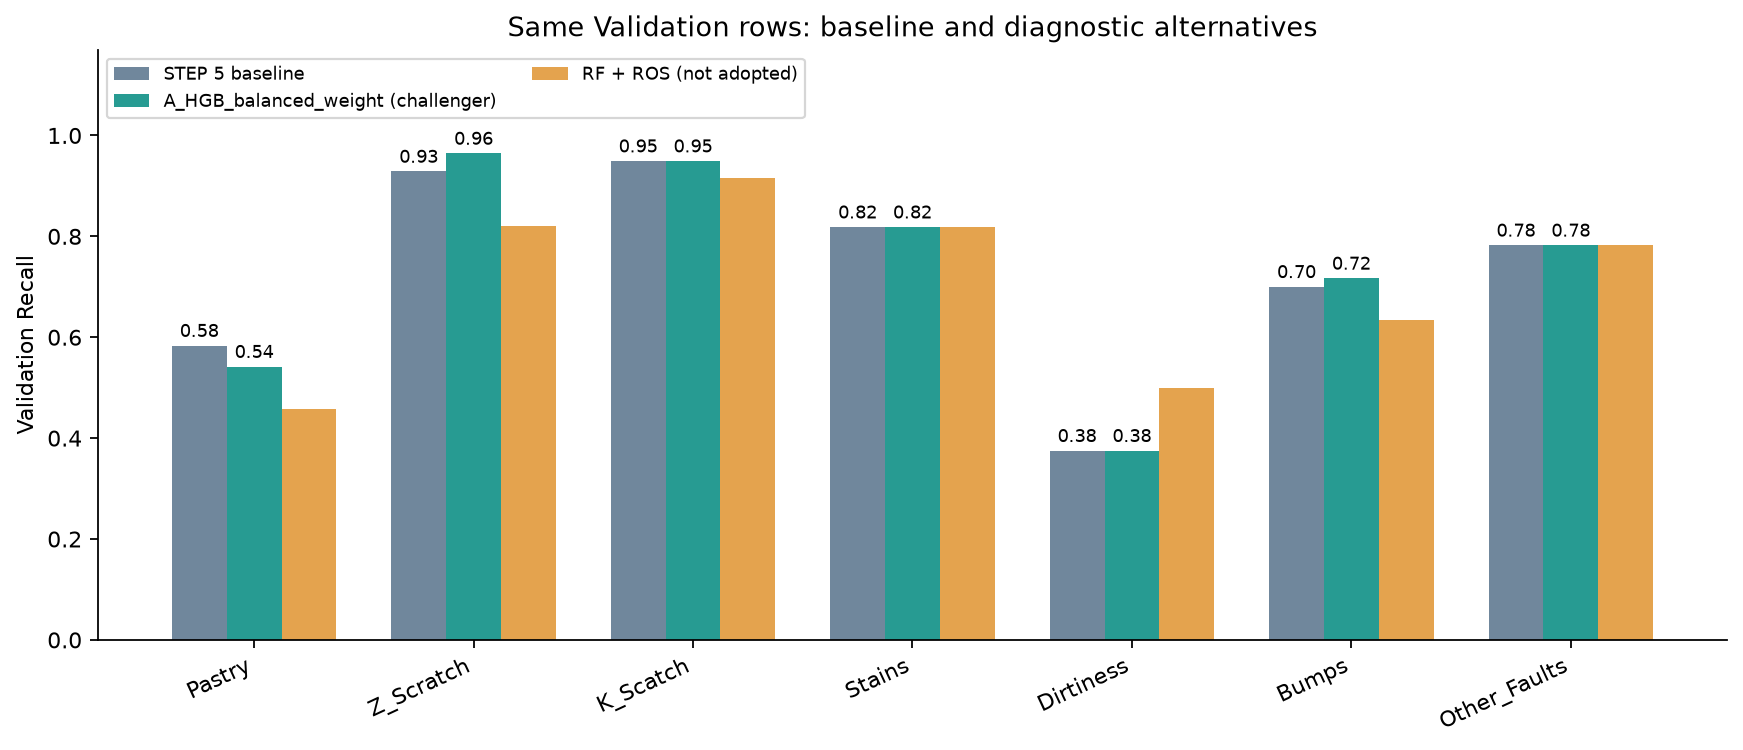

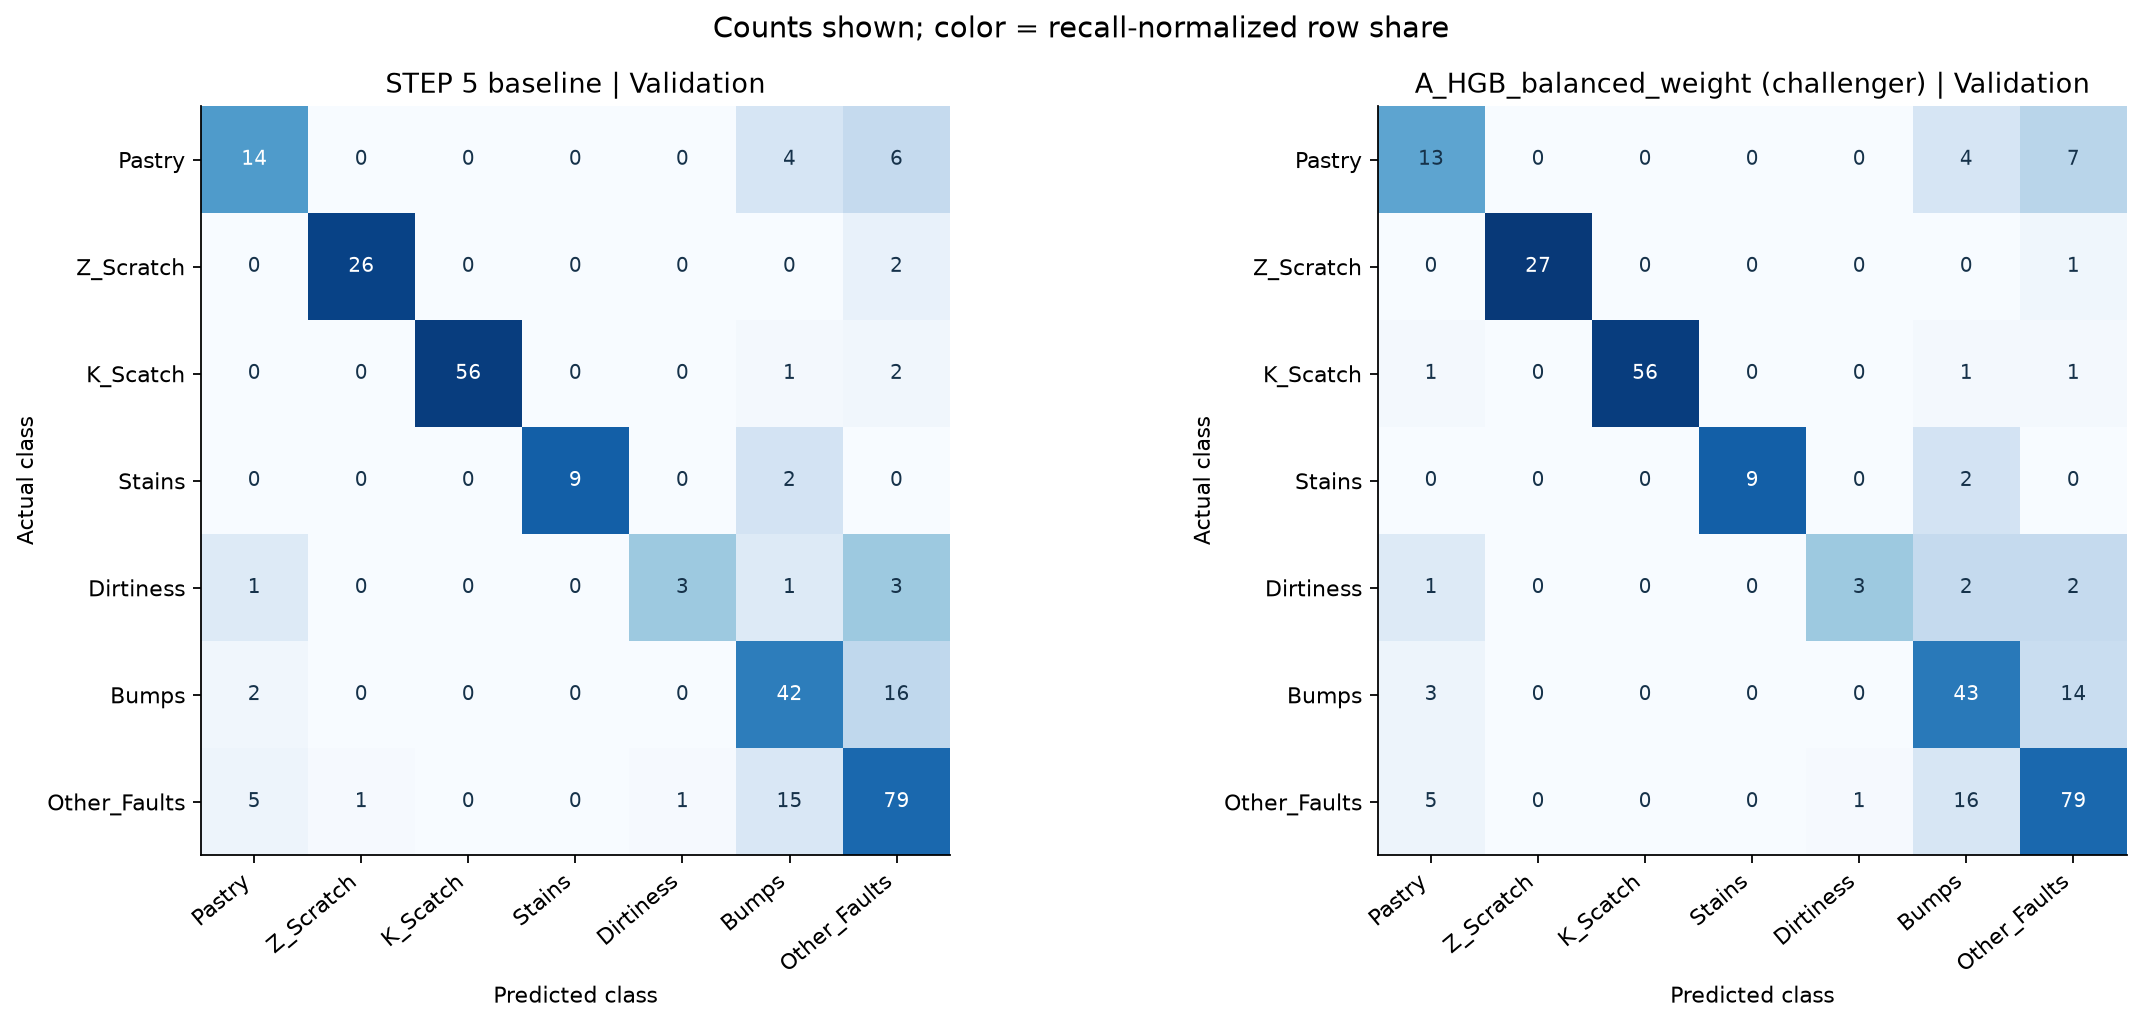

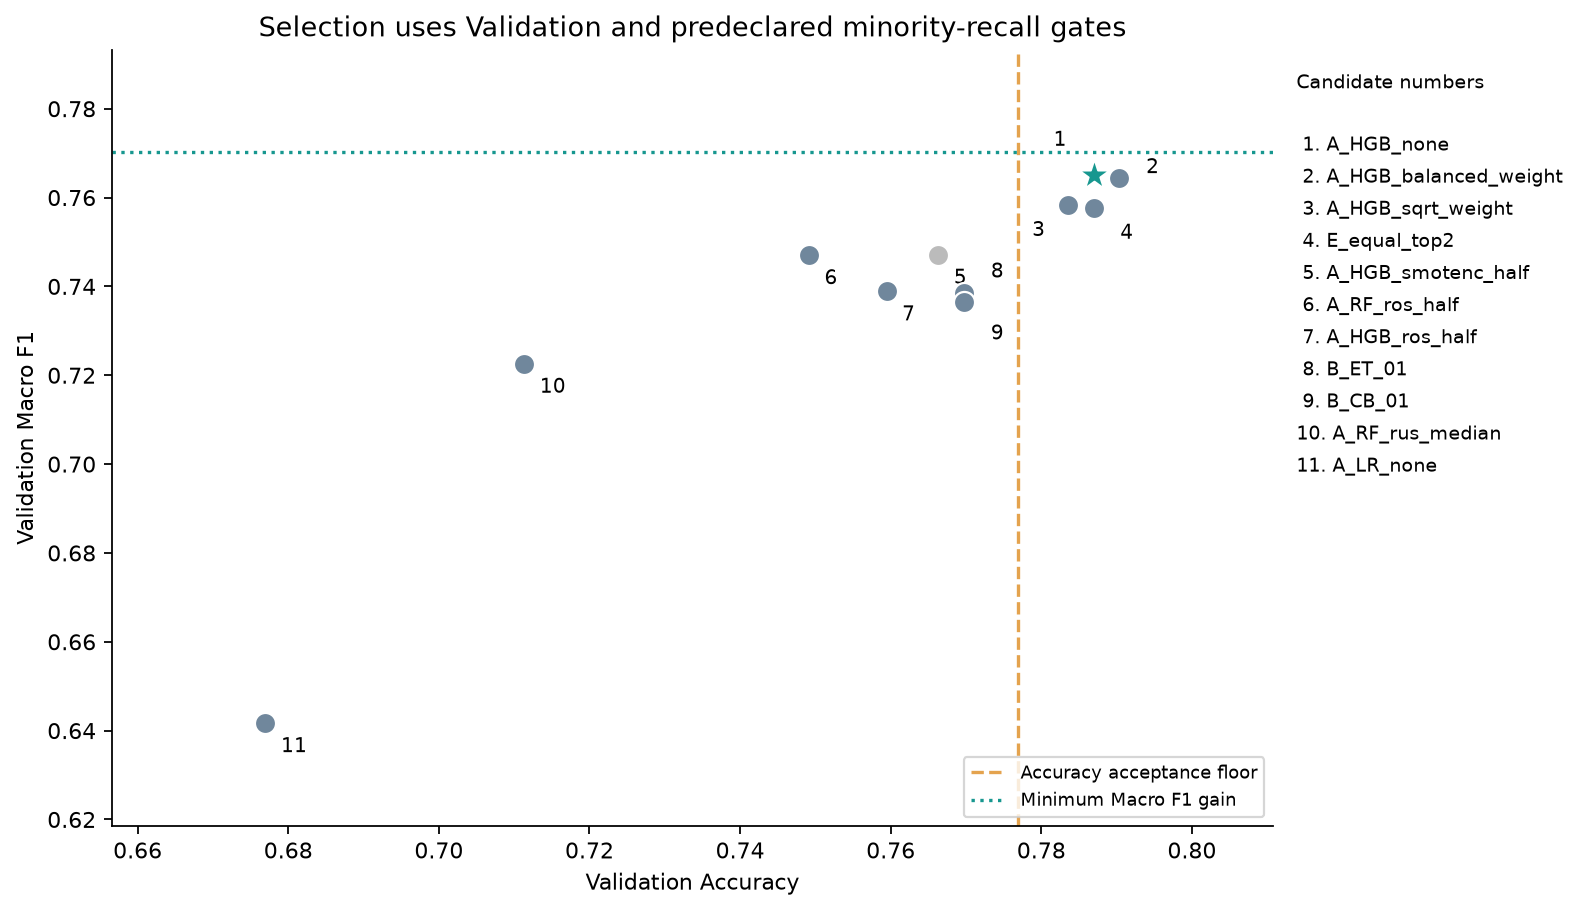

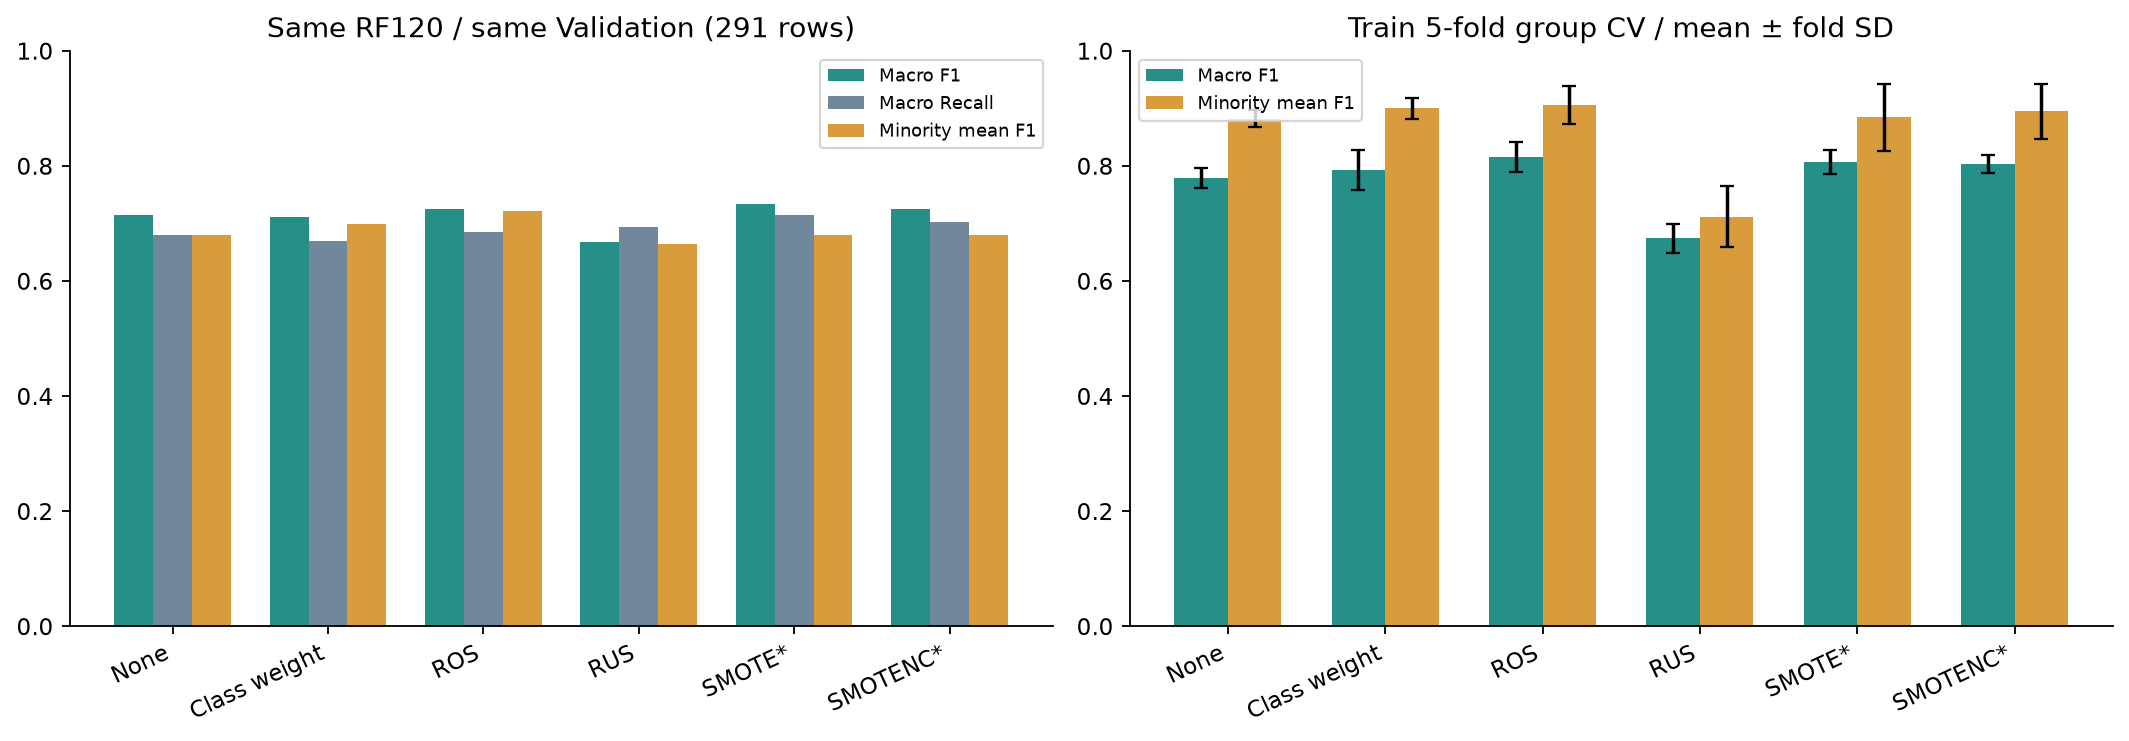

보고서: STEP6_클래스불균형_성능개선_실측보고서.html


,model,valid_accuracy,valid_macro_f1,valid_rare_recall,test_accuracy,test_macro_f1
0,STEP5 baseline,0.7869,0.7651,0.5966,0.8048,0.8198
1,STEP6 selected,0.7869,0.7651,0.5966,0.8048,0.8198


In [17]:
report_path,figures=build_report(data,selection,test_result)
for path in figures:display(Image(filename=str(path)))
print('보고서:',report_path.name)
display(pd.read_csv(e.OUT/'19_step5_step6_summary.csv').round(4))

## 12. 실제 결과에 따른 판단과 인수인계

소수 유형 개선과 전체 성능 사이의 교환 관계, CV와 Valid의 불일치를 함께 해석합니다. 기준선을 유지하는 결론도 불균형 처리 실험의 결과입니다. 성능이 좋아 보이는 Test 조건을 다시 고르지 않습니다.

전체 패키지에는 37개 설정, 모든 CV·OOF 예측·학습 감사, Valid 비교·혼동행렬·확률, 차이 구간·민감도, 원시 입력용 모델, 예측 스크립트와 보고서를 포함합니다. 새로운 생산 배치로 평가해야 현장 개선 여부를 판단할 수 있습니다.

In [18]:
manifest=json.loads((e.OUT/'execution_manifest.json').read_text(encoding="utf-8-sig"))
assert manifest['source_hashes_unchanged']
assert len(screen)==37
assert len(comparison)==len(promoted)+1
assert not selection['test_used_to_select']
assert selection['training_rows']==1358
print('원본·STEP5 hash 보존, 37조건, CV·Valid 비교, Test 전 선정 기록 검증 통과')
print('CV 모델 적합 경고:',manifest['fit_warning_count'])
status='개선 후보 채택' if selection['meaningful_valid_gain'] else '사전 개선 기준 미충족 → STEP 5 기준선 유지'
display(HTML(f"<div style='padding:20px;background:#edf7f4;border-left:5px solid #279b92'><b>{status}</b><br>선정: {selection['candidate']}<br>Valid Accuracy {selection['valid_accuracy']:.2%}, Macro F1 {selection['valid_macro_f1']:.4f}<br>기존 Test 참고 Accuracy {test_result['accuracy']:.2%}, Macro F1 {test_result['macro_f1']:.4f}<br>새로운 독립 검증에는 신규 배치 데이터가 필요합니다.</div>"))

원본·STEP5 hash 보존, 37조건, CV·Valid 비교, Test 전 선정 기록 검증 통과
CV 모델 적합 경고: 0


## 13. 이전 신규 모델 탐색 자료와의 관계

이전에 만든 **ExtraTrees + XGBoost(2:1)** 모델은 원시 입력을 사용해 **Train+Valid 1,649건**으로 학습하고 개발 OOF **Accuracy**를 우선하여 선택했습니다. 기존 Test 참고 결과는 **81.85%(239/292), Macro F1 0.8311**이며, 그 실험도 Test 공개 이후의 탐색이었습니다.

이번 STEP 6는 직전 STEP 5와 **같은 Train 1,358건·27개 입력**으로 불균형 처리 효과를 비교하고 **Valid Macro F1·희소 유형 Recall**로 채택 여부를 판단했습니다. 표본 수·선택 목표·규칙이 달라 두 Test 수치를 불균형 처리의 효과나 모델 우열로 해석하지 않습니다. 이전 탐색의 프로토콜·선정·성능 기록은 `prior_search_reference/`에 보존했습니다. 운영 후보를 정하려면 같은 조건과 신규 생산 자료에서 다시 비교해야 합니다.